In [2]:
import xarray as xr
import numpy as np
import cftime
import xesmf as xe
import TCs
import matplotlib.pyplot as plt
from scipy.stats import linregress
from scipy import stats
import pandas as pd

import matplotlib.gridspec as gridspec
from matplotlib.patches import Rectangle
import cartopy.crs as ccrs
import matplotlib.ticker as mticker
import cartopy.feature as cfeature
import matplotlib.colors as mcolors
from matplotlib.colors import TwoSlopeNorm
from matplotlib.lines import Line2D

In [1]:
colors = {
    'posIPO':'#ea801c', 'negIPO':'#ffbb6f', 
    'noIPO':'#7f7f7f', 
    'posAMO':'#2066a8', 'negAMO':'#8cc5e3',
}

In [14]:
ds1 = xr.open_dataset("Figure2_1.nc")
ds2 = xr.open_dataset("Figure2_2.nc")

hist_annual_time = np.arange('1961', '2021', dtype='datetime64[Y]')
hist_monthly_time = np.arange('1961', '2021', dtype='datetime64[M]')
future_annual_time = np.arange('2031', '2051', dtype='datetime64[Y]')
future_monthly_time = np.arange('2031', '2051', dtype='datetime64[M]')

Text(0.03, 0.19, 'c')

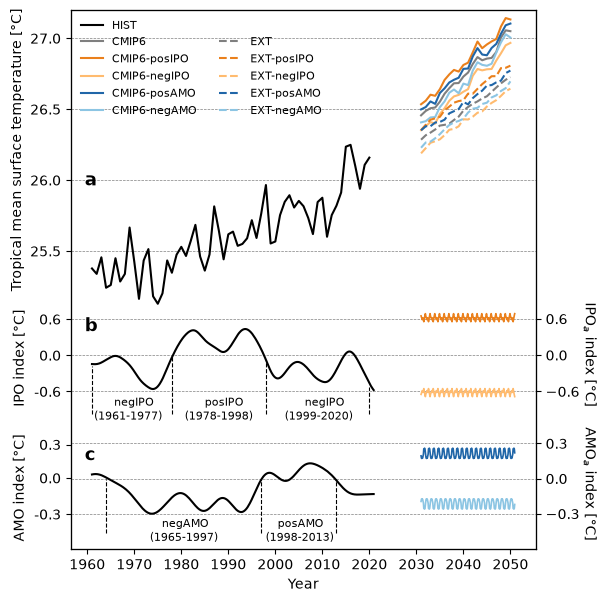

In [22]:
fig, axs = plt.subplots(figsize=(6,7)) 

axs.plot(hist_annual_time, ds1['TS_hist'], color='black', label='HIST')

for ii,itrend in enumerate(['CMIP6', 'Hadley']):
    for jj,ipo in enumerate(['noIPO', 'posIPO', 'negIPO', 'posAMO', 'negAMO']):
        my_ts_sd = ds1[f'TS_{itrend}_{ipo}']
        label_trend = itrend if itrend=='CMIP6' else 'EXT'
        axs.plot(future_annual_time, my_ts_sd, color=colors[f'{ipo}'], linestyle='solid' if itrend=='CMIP6' else 'dashed', 
                   label=f'{label_trend}-{ipo}' if ipo!='noIPO' else f'{label_trend}', 
                 linewidth=1.5)
axs.set_ylim(23.4,27.2)
axs.set_yticks(np.arange(25.5,27.3, 0.5))
for y in [25.5, 26, 26.5, 27]:
    axs.axhline(y, color='grey', linewidth=0.5, linestyle='dashed', zorder=0)
axs.set_ylabel('Tropical mean surface temperature [°C]', fontsize=10)
axs.yaxis.set_label_coords(-0.1, 0.74)
axs.set_xlabel('Year')
# axs.set_title('Global annual mean SST', y=1.03)

handles, labels = axs.get_legend_handles_labels()
leg1 = axs.legend(
    handles[:1], labels[:1],
    loc='upper left', fontsize=8, frameon=False
)
leg2 = axs.legend(
    handles[1:], labels[1:], ncol=2,
    loc='upper left', bbox_to_anchor=(0, 0.97), fontsize=8, frameon=False
)
axs.add_artist(leg1)

ax2 = axs.twinx()
ax2.plot(hist_monthly_time, ds2['TPI_hist'], color='black', zorder=10)
ax2.set_ylim(-3.7+0.5, 5.2+0.5)
ax2.set_yticks(np.arange(-0.6, 0.7, 0.6))
axs.text(-0.125, 0.27, 'IPO index [°C]', rotation=90, fontsize=10, transform=axs.transAxes)
ax2.set_ylabel(r'IPO$_a$ index [°C]', rotation=270, fontsize=10)
ax2.yaxis.set_label_coords(1.13, 0.36)
ax2.tick_params(axis='y', labelsize=10)
for y in [-0.6, 0, 0.6]:
    ax2.axhline(y, color='grey', linewidth=0.5, linestyle='dashed')
# ax2.fill_between(hist_monthly_time, TPI_hicam['hist'].where(TPI_hicam['hist']<0), 0, color='skyblue', alpha=0.15)
# ax2.fill_between(hist_monthly_time, 0, TPI_hicam['hist'].where(TPI_hicam['hist']>0), color='coral', alpha=0.15)
ax2.axvline(np.datetime64('1961'), ymin=0.25, ymax=0.34, color='black', linewidth=0.8, linestyle='dashed')
ax2.axvline(np.datetime64('1978'), ymin=0.25, ymax=0.36, color='black', linewidth=0.8, linestyle='dashed')
ax2.axvline(np.datetime64('1998'), ymin=0.25, ymax=0.35, color='black', linewidth=0.8, linestyle='dashed')
ax2.axvline(np.datetime64('2020'), ymin=0.25, ymax=0.30, color='black', linewidth=0.8, linestyle='dashed')
ax2.annotate('     negIPO\n(1961-1977)', [0.05,0.24], xycoords='axes fraction', fontsize=8)
ax2.annotate('     posIPO\n(1978-1998)', [0.245,0.24], xycoords='axes fraction', fontsize=8)
ax2.annotate('     negIPO\n(1999-2020)', [0.46,0.24], xycoords='axes fraction', fontsize=8)
for ii,iipo in enumerate(['pos','neg']):
    ax2.plot(future_monthly_time, ds2[f'TPI_{iipo}'], color=colors[f'{iipo}IPO'], 
             linestyle='solid', linewidth=1.2)

ax3 = axs.twinx()
ax3.plot(hist_monthly_time, ds2['AMO_hist'], color='black', zorder=10)
for y in [-0.3, 0, 0.3]:
    ax3.axhline(y, color='grey', linewidth=0.5, linestyle='dashed')
ax3.set_ylim(-0.6, 4)
axs.set_yticks([23.645, 23.90, 24.136, 
                24.51, 24.765, 25.02, 
                25.5, 26, 26.5, 27])
axs.set_yticklabels(['-0.3', '0.0', '0.3', '-0.6', '0.0', '0.6', '25.5', '26.0', '26.5', '27.0'])
ax3.set_yticks(np.arange(-0.3, 0.4, 0.3))
axs.text(-0.125, 0.02, 'AMO index [°C]', rotation=90, fontsize=10, transform=axs.transAxes)
ax3.set_ylabel(r'AMO$_a$ index [°C]', rotation=270, fontsize=10)
ax3.yaxis.set_label_coords(1.13, 0.12)
# axs.tick_params(axis='y', labelleft=True, labelsize=10)
ax3.axvline(np.datetime64('1964'), ymin=0.03, ymax=0.13, color='black', linewidth=0.8, linestyle='dashed')
ax3.axvline(np.datetime64('1997'), ymin=0.03, ymax=0.13, color='black', linewidth=0.8, linestyle='dashed')
ax3.axvline(np.datetime64('2013'), ymin=0.03, ymax=0.13, color='black', linewidth=0.8, linestyle='dashed')
ax3.annotate('   negAMO\n(1965-1997)', [0.17,0.015], xycoords='axes fraction', fontsize=8)
ax3.annotate('   posAMO\n(1998-2013)', [0.419,0.015], xycoords='axes fraction', fontsize=8)
for ii,iamo in enumerate(['pos','neg']):
    ax3.plot(future_monthly_time, ds2[f'AMO_{iamo}'], color=colors[f'{iamo}AMO'], 
             linestyle='solid', linewidth=1.2)

ax3.annotate('a', xy=(0.03, 0.7), xycoords='axes fraction', fontsize=13, fontweight='bold', ha='left', va='top')
ax3.annotate('b', xy=(0.03, 0.43), xycoords='axes fraction', fontsize=13, fontweight='bold', ha='left', va='top')
ax3.annotate('c', xy=(0.03, 0.19), xycoords='axes fraction', fontsize=13, fontweight='bold', ha='left', va='top')

# plt.savefig(f'Figure2.png', bbox_inches='tight', dpi=300)